# TSN DRL Training and Evaluation

This notebook runs an end-to-end training/evaluation workflow:
1. Check kernel/runtime.
2. Ensure RL deps are installed.
3. Train PPO using `instance1.json`, `instance2.json`, `instance3.json`.
4. Evaluate on `instance4.json` and `instance5.json` with reward-component metrics.
5. Plot training/evaluation diagnostics and schedule before/after.

In [9]:
import sys
print(sys.version)

3.9.25 (main, Nov  3 2025, 22:33:05) 
[GCC 11.2.0]


In [10]:
%pip install stable-baselines3 gymnasium

Note: you may need to restart the kernel to use updated packages.


In [11]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import stable_baselines3 as sb3
from stable_baselines3 import PPO

from tsn_scheduling_problem import TSNScheduling
from env import TSNDefragEnv

print('stable-baselines3:', sb3.__version__)

stable-baselines3: 2.7.0


In [ ]:
import importlib
import env as env_module
importlib.reload(env_module)
TSNDefragEnv = env_module.TSNDefragEnv

TRAIN_INSTANCE_FILES = [f"instance{i}.json" for i in [1, 2, 3]]
TEST_INSTANCE_FILES = [f"instance{i}.json" for i in [4, 5]]
TRAIN_STEPS_PER_INSTANCE = 3000
EVAL_STEPS = 60
DETERMINISTIC_EVAL = False

REWARD_WEIGHTS = {
    'w1_admission': 2.0,
    'w2_frag': 1.0,
    'w3_shift': 0.05,
    'w4_moved': 0.2,
    'w5_invalid': 100.0,
}

problem = TSNScheduling('uc_config.cfg')

def make_env(instance_path):
    uc = problem.import_scheduling_usecase(instance_path)
    env = TSNDefragEnv(
        problem=problem,
        usecase=uc,
        single_move_per_step=False,
        reward_mode='paper_simple',
        reward_weights=REWARD_WEIGHTS,
        init_from_usecase_schedule=True,
        move_penalty=0.005,
    )
    return env

for fp in TRAIN_INSTANCE_FILES + TEST_INSTANCE_FILES:
    if not os.path.exists(fp):
        print(f'WARNING: {fp} not found')

In [ ]:
model = None

for idx, train_fp in enumerate(TRAIN_INSTANCE_FILES):
    if not os.path.exists(train_fp):
        print(f'Skipping missing train instance: {train_fp}')
        continue

    train_env = make_env(train_fp)
    obs, _ = train_env.reset()

    if model is None:
        model = PPO(
            policy='MultiInputPolicy',
            env=train_env,
            verbose=1,
            n_steps=256,
            batch_size=64,
            learning_rate=3e-4,
            gamma=0.99,
            device='cpu',
        )
    else:
        model.set_env(train_env)

    model.learn(total_timesteps=TRAIN_STEPS_PER_INSTANCE, reset_num_timesteps=False)
    print(f'Trained on {train_fp} ({idx+1}/{len(TRAIN_INSTANCE_FILES)})')

os.makedirs('outputs', exist_ok=True)
model.save('outputs/tsn_training_eval_ppo_model')
print('Model saved to outputs/tsn_training_eval_ppo_model')

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
----------------------------
| time/              |     |
|    fps             | 285 |
|    iterations      | 1   |
|    time_elapsed    | 0   |
|    total_timesteps | 256 |
----------------------------
----------------------------------------
| time/                   |            |
|    fps                  | 234        |
|    iterations           | 2          |
|    time_elapsed         | 2          |
|    total_timesteps      | 512        |
| train/                  |            |
|    approx_kl            | 27246152.0 |
|    clip_fraction        | 0.946      |
|    clip_range           | 0.2        |
|    entropy_loss         | -4.09e+03  |
|    explained_variance   | 0.00308    |
|    learning_rate        | 0.0003     |
|    loss                 | -0.0979    |
|    n_updates            | 10         |
|    policy_gradient_loss | 0.13       |
|    std                  | 1          |
|    v

In [ ]:
def rollout_metrics(env, model, eval_steps=60, instance_name='unknown', deterministic_eval=False):
    obs, _ = env.reset()
    before_gaps = env._count_gaps()
    rewards = []
    moved_total = 0
    changes = []
    comp_delta_adm = []
    comp_delta_frag = []
    comp_shift = []
    comp_moved = []
    comp_invalid = []
    comp_invalid_new = []

    for step_idx in range(eval_steps):
        action, _ = model.predict(obs, deterministic=deterministic_eval)
        obs, reward, terminated, truncated, info = env.step(action)
        rewards.append(float(reward))
        moved_total += int(info.get('n_moved', 0))

        comp_delta_adm.append(float(info.get('delta_admission_fit', 0.0)))
        comp_delta_frag.append(float(info.get('delta_frag_score', 0.0)))
        comp_shift.append(float(info.get('shift_cost', 0.0)))
        comp_moved.append(float(info.get('moved_streams_matrix', info.get('n_moved', 0))))
        comp_invalid.append(float(info.get('invalid', 0)))
        comp_invalid_new.append(float(info.get('invalid_new', 0)))

        move_events = info.get('moved_actions') or []
        if move_events:
            for ev in move_events:
                changes.append({
                    'instance': instance_name,
                    'step': int(step_idx),
                    'stream_id': int(ev.get('stream_id')) if ev.get('stream_id') is not None else None,
                    'port_id': int(ev.get('port_id')) if ev.get('port_id') is not None else None,
                    'old_start_ns': int(ev.get('old_start_ns')) if ev.get('old_start_ns') is not None else None,
                    'new_start_ns': int(ev.get('new_start_ns')) if ev.get('new_start_ns') is not None else None,
                    'delta_start_ns': int(ev.get('delta_start_ns')) if ev.get('delta_start_ns') is not None else None,
                    'reward': float(reward),
                })

        if terminated or truncated:
            break

    after_gaps = env._count_gaps()
    n_steps = len(rewards)
    metrics = {
        'steps': n_steps,
        'reward_sum': float(np.sum(rewards)),
        'reward_mean': float(np.mean(rewards) if rewards else 0.0),
        'gaps_before': int(before_gaps),
        'gaps_after': int(after_gaps),
        'gap_improvement': int(before_gaps - after_gaps),
        'moves': int(moved_total),
        'moves_per_step': float(moved_total / max(1, n_steps)),
        'delta_admission_mean': float(np.mean(comp_delta_adm) if comp_delta_adm else 0.0),
        'delta_frag_mean': float(np.mean(comp_delta_frag) if comp_delta_frag else 0.0),
        'shift_cost_mean': float(np.mean(comp_shift) if comp_shift else 0.0),
        'moved_streams_mean': float(np.mean(comp_moved) if comp_moved else 0.0),
        'invalid_rate': float(np.mean(comp_invalid) if comp_invalid else 0.0),
        'invalid_new_rate': float(np.mean(comp_invalid_new) if comp_invalid_new else 0.0),
    }
    return metrics, changes

results = []
all_changes = []
for fp in TEST_INSTANCE_FILES:
    if not os.path.exists(fp):
        continue
    env_i = make_env(fp)
    m, ch = rollout_metrics(
        env_i,
        model,
        eval_steps=EVAL_STEPS,
        instance_name=fp,
        deterministic_eval=DETERMINISTIC_EVAL,
    )
    m['instance'] = fp
    results.append(m)
    all_changes.extend(ch)

metrics_df = pd.DataFrame(results)[
    ['instance','steps','reward_sum','reward_mean','gaps_before','gaps_after','gap_improvement','moves','moves_per_step',
     'delta_admission_mean','delta_frag_mean','shift_cost_mean','moved_streams_mean','invalid_rate','invalid_new_rate']
 ]
changes_df = pd.DataFrame(
    all_changes,
    columns=['instance','step','stream_id','port_id','old_start_ns','new_start_ns','delta_start_ns','reward']
  )

print('Move records:', len(changes_df))
print('Deterministic eval:', DETERMINISTIC_EVAL)
metrics_df

Move records: 911
Deterministic eval: False


,instance,steps,reward_sum,reward_mean,gaps_before,gaps_after,gap_improvement,moves,moves_per_step,delta_admission_mean,delta_frag_mean,shift_cost_mean,moved_streams_mean,invalid_rate,invalid_new_rate
0,instance1.json,60,-142.478972,-2.374650,195,142,53,156,2.600000,0.0,0.000140,3.762462,2.600000,1.0,0.016667
1,instance2.json,60,-153.661378,-2.561023,170,119,51,213,3.550000,0.0,-0.000048,3.686169,3.550000,1.0,0.016667
2,instance3.json,60,-147.772341,-2.462872,183,136,47,176,2.933333,0.0,-0.001003,4.170720,2.933333,1.0,0.016667
3,instance4.json,60,-148.734939,-2.478916,188,132,56,186,3.100000,0.0,-0.000824,3.828498,3.100000,1.0,0.016667
4,instance5.json,60,-148.515688,-2.475261,187,140,47,180,3.000000,0.0,-0.002134,4.129208,3.000000,1.0,0.016667


In [ ]:
os.makedirs('outputs', exist_ok=True)

metrics_path = 'outputs/tsn_training_eval_metrics.csv'
changes_path = 'outputs/tsn_training_eval_changes.csv'

metrics_df.to_csv(metrics_path, index=False)
changes_df.to_csv(changes_path, index=False)

print('Saved metrics:', metrics_path)
print('Saved changes:', changes_path)
print('Changes sample:')
changes_df.head(10)

Saved metrics: outputs/first_test_metrics.csv
Saved changes: outputs/first_test_changes.csv
Changes sample:


,instance,step,stream_id,port_id,old_start_ns,new_start_ns,delta_start_ns,reward
0,instance1.json,0,0,16,57158,0,-57158,-112.768856
1,instance1.json,0,1,2,16772,0,-16772,-112.768856
2,instance1.json,0,2,1,60815,0,-60815,-112.768856
3,instance1.json,0,3,1,27871,0,-27871,-112.768856
4,instance1.json,0,4,6,44479,0,-44479,-112.768856
5,instance1.json,0,5,2,11930,0,-11930,-112.768856
6,instance1.json,0,6,15,19751,0,-19751,-112.768856
7,instance1.json,0,7,14,32655,0,-32655,-112.768856
8,instance1.json,0,8,9,12864,0,-12864,-112.768856
9,instance1.json,0,9,3,17070,0,-17070,-112.768856


Saved: outputs/first_test_metrics_plots.png


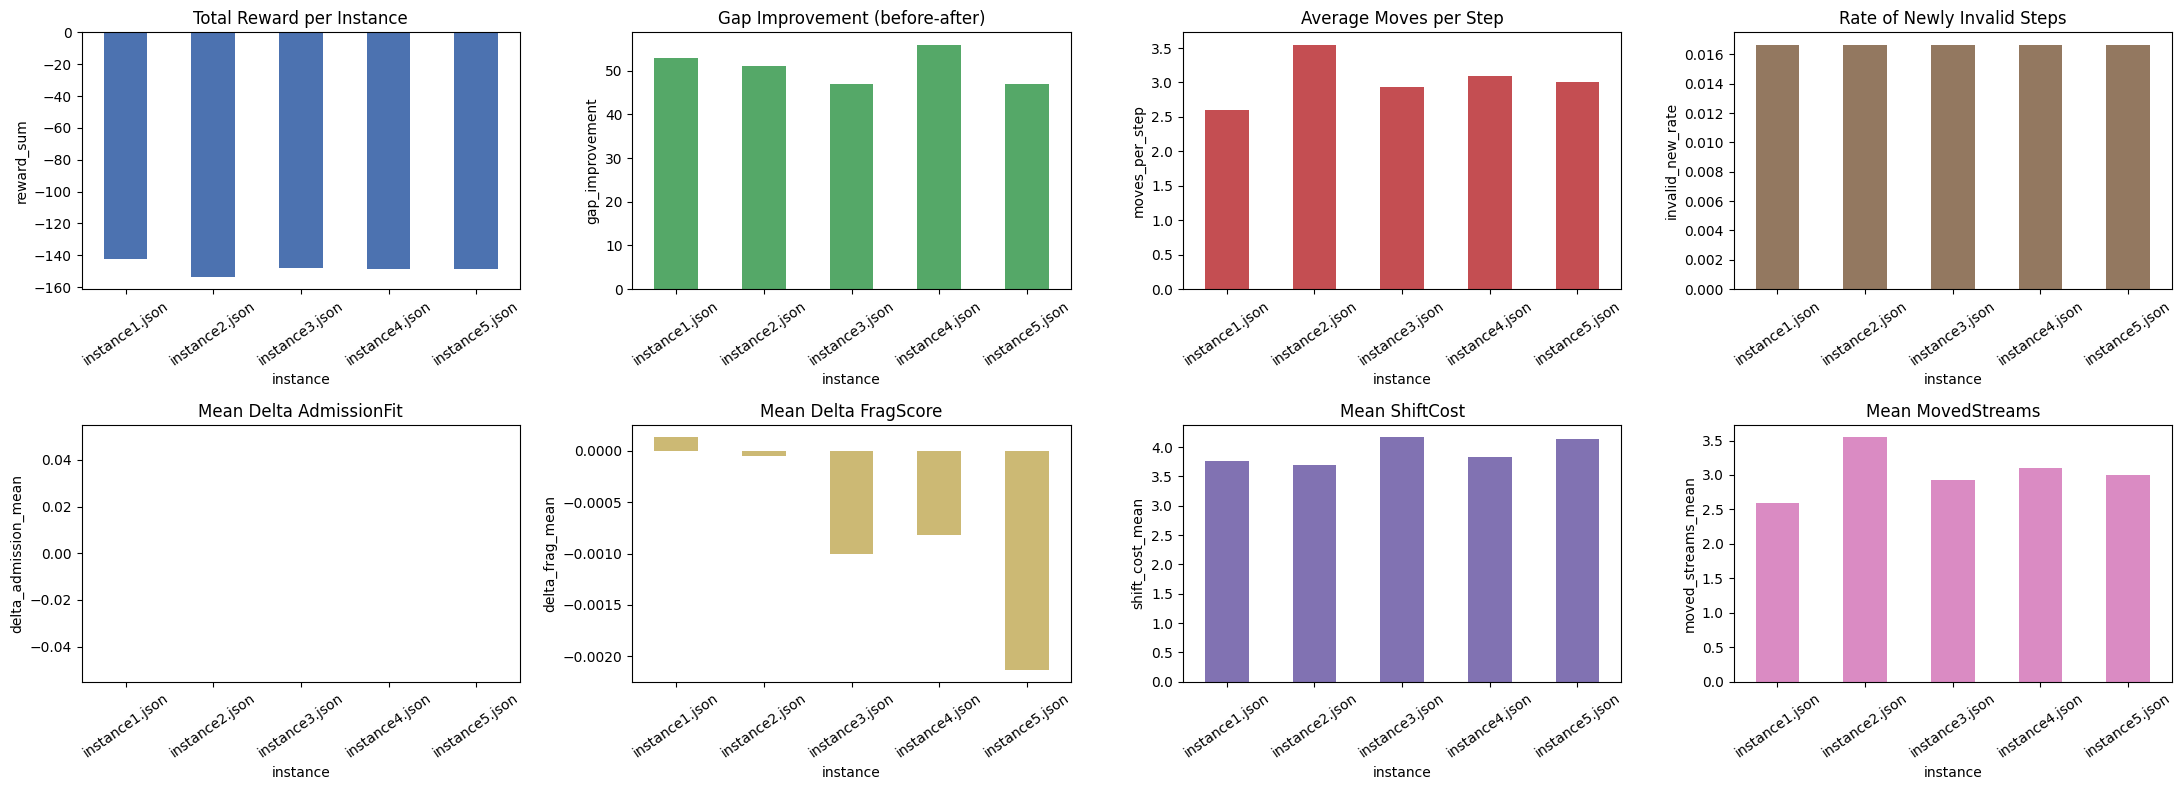

Saved: outputs/first_test_move_diagnostics.png


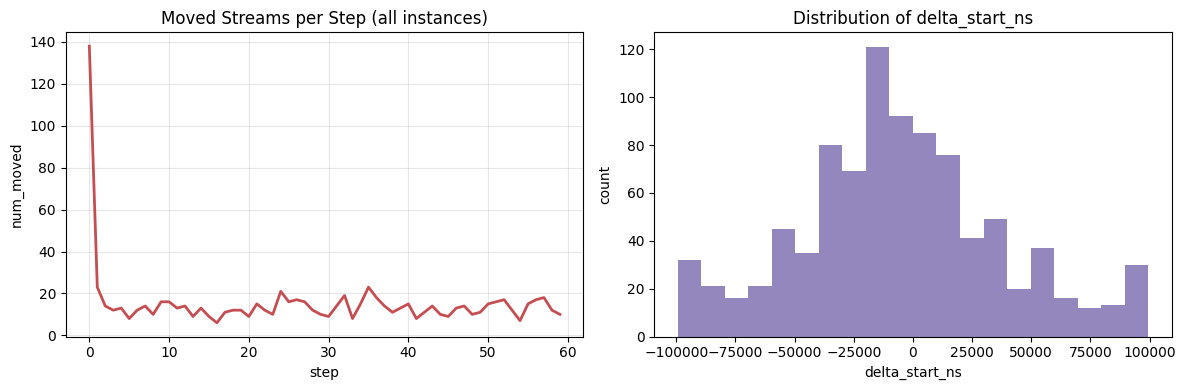

In [ ]:
# Quick metric plots across instances
if not metrics_df.empty:
    fig, axes = plt.subplots(2, 4, figsize=(22, 8))

    metrics_df.plot(
        x='instance', y='reward_sum', kind='bar', legend=False, ax=axes[0, 0], color='#4C72B0'
    )
    axes[0, 0].set_title('Total Reward per Instance')
    axes[0, 0].set_ylabel('reward_sum')
    axes[0, 0].tick_params(axis='x', rotation=35)

    metrics_df.plot(
        x='instance', y='gap_improvement', kind='bar', legend=False, ax=axes[0, 1], color='#55A868'
    )
    axes[0, 1].set_title('Gap Improvement (before-after)')
    axes[0, 1].set_ylabel('gap_improvement')
    axes[0, 1].tick_params(axis='x', rotation=35)

    metrics_df.plot(
        x='instance', y='moves_per_step', kind='bar', legend=False, ax=axes[0, 2], color='#C44E52'
    )
    axes[0, 2].set_title('Average Moves per Step')
    axes[0, 2].set_ylabel('moves_per_step')
    axes[0, 2].tick_params(axis='x', rotation=35)

    metrics_df.plot(
        x='instance', y='invalid_new_rate', kind='bar', legend=False, ax=axes[0, 3], color='#937860'
    )
    axes[0, 3].set_title('Rate of Newly Invalid Steps')
    axes[0, 3].set_ylabel('invalid_new_rate')
    axes[0, 3].tick_params(axis='x', rotation=35)

    metrics_df.plot(
        x='instance', y='delta_admission_mean', kind='bar', legend=False, ax=axes[1, 0], color='#64B5CD'
    )
    axes[1, 0].set_title('Mean Delta AdmissionFit')
    axes[1, 0].set_ylabel('delta_admission_mean')
    axes[1, 0].tick_params(axis='x', rotation=35)

    metrics_df.plot(
        x='instance', y='delta_frag_mean', kind='bar', legend=False, ax=axes[1, 1], color='#CCB974'
    )
    axes[1, 1].set_title('Mean Delta FragScore')
    axes[1, 1].set_ylabel('delta_frag_mean')
    axes[1, 1].tick_params(axis='x', rotation=35)

    metrics_df.plot(
        x='instance', y='shift_cost_mean', kind='bar', legend=False, ax=axes[1, 2], color='#8172B2'
    )
    axes[1, 2].set_title('Mean ShiftCost')
    axes[1, 2].set_ylabel('shift_cost_mean')
    axes[1, 2].tick_params(axis='x', rotation=35)

    metrics_df.plot(
        x='instance', y='moved_streams_mean', kind='bar', legend=False, ax=axes[1, 3], color='#DA8BC3'
    )
    axes[1, 3].set_title('Mean MovedStreams')
    axes[1, 3].set_ylabel('moved_streams_mean')
    axes[1, 3].tick_params(axis='x', rotation=35)

    plt.tight_layout()
    plt.savefig('outputs/tsn_training_eval_metrics_plots.png', dpi=140, bbox_inches='tight')
    print('Saved: outputs/tsn_training_eval_metrics_plots.png')
    plt.show()
else:
    print('metrics_df is empty, skipping plots.')

# Extra diagnostics from move logs
if not changes_df.empty:
    fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4))

    moves_by_step = changes_df.groupby('step').size()
    moves_by_step.plot(ax=axes2[0], color='#C44E52', linewidth=2)
    axes2[0].set_title('Moved Streams per Step (all instances)')
    axes2[0].set_xlabel('step')
    axes2[0].set_ylabel('num_moved')
    axes2[0].grid(alpha=0.3)

    changes_df['delta_start_ns'].dropna().plot(
        kind='hist', bins=20, ax=axes2[1], color='#8172B2', alpha=0.85
    )
    axes2[1].set_title('Distribution of delta_start_ns')
    axes2[1].set_xlabel('delta_start_ns')
    axes2[1].set_ylabel('count')

    plt.tight_layout()
    plt.savefig('outputs/tsn_training_eval_move_diagnostics.png', dpi=140, bbox_inches='tight')
    print('Saved: outputs/tsn_training_eval_move_diagnostics.png')
    plt.show()
else:
    print('changes_df is empty, skipping move diagnostics.')





Saved: outputs/first_test_schedule_before.png
Saved: outputs/first_test_schedule_after.png


In [ ]:
plot_instance = TEST_INSTANCE_FILES[0]
env_plot = make_env(plot_instance)

obs, _ = env_plot.reset()
before_sched = env_plot.get_combined_schedule()
fig_before, _ = before_sched.plot()

for _ in range(EVAL_STEPS):
    action, _ = model.predict(obs, deterministic=DETERMINISTIC_EVAL)
    obs, reward, terminated, truncated, info = env_plot.step(action)
    if terminated or truncated:
        break

after_sched = env_plot.get_combined_schedule()
fig_after, _ = after_sched.plot()

fig_before.savefig('outputs/tsn_training_eval_schedule_before.png', dpi=140, bbox_inches='tight')
fig_after.savefig('outputs/tsn_training_eval_schedule_after.png', dpi=140, bbox_inches='tight')

print('Saved: outputs/tsn_training_eval_schedule_before.png')
print('Saved: outputs/tsn_training_eval_schedule_after.png')
print('Deterministic eval:', DETERMINISTIC_EVAL)